# Notebook 2 — Feature Engineering & Leakage Audit

**This notebook's job:** turn the validated panel into a feature matrix in which every value at row *t* is provably observable at the close of *t*. It also fixes the feature groups used by the ablation study, *before* any model is fit.

| | |
|---|---|
| **Inputs** | `data/processed/panel.parquet`, `targets.parquet`, `nb01_meta.json` (Notebook 1) |
| **Outputs** | `features.parquet` · `feature_catalog.csv` · `feature_sets.json` · `leakage_audit.csv` |
| **Next** | Notebook 3 fits benchmarks and ML models on these features |

**Design decisions driven by Notebook 1 results (2015–2022)**

| Notebook 1 finding | Feature response |
|---|---|
| Overnight session ≈ 43% of close-to-close variance | Yang-Zhang estimator; separate overnight and open-to-close realised variance; overnight-share feature |
| Leverage effect: corr(r<sub>t</sub>, future RV₂₀) ≈ −0.13 | Signed downside return; negative realised semivariance |
| Log-variance is near-Gaussian | All variance features stored as **log annualised variance**, the same scale as the target |
| Clean VIX, VIX9D, VIX3M from CBOE | Term-structure slopes (VIX9D/VIX, VIX/VIX3M) and an implied-minus-trailing-realised spread |

**What is deliberately *not* here:** volatility-regime labels. Their 33/67% thresholds must be estimated inside each training fold, so Notebook 3 builds them in the walk-forward loop. Computing them here from the full sample would leak.

## 6. Feature sets for the ablation study (fixed now)

The ablation experiments of Notebook 4 are defined **here, before any model is fit**, so they cannot be tuned to make a result look good. The HAR feature sets for the econometric benchmarks are fixed here too.

| Set | Contents | Question it answers |
|---|---|---|
| E1 | Close-to-close RV only | How far does plain historical volatility go? |
| E2 | + returns, range estimators, dynamics | Do OHLC-based estimators add information? |
| E3 | + implied vol (VIX family) | **Does option-implied information improve forecasts?** |
| E4 | + volume, momentum = all features | Does anything beyond volatility matter? |
| E_noVIX | All minus implied | Same question as E3, asked from the other side |
| HAR | log RV daily, weekly, monthly | Corsi (2009) benchmark |
| HAR-X | HAR + log VIX² | HAR augmented with implied variance |

## 0. Setup

In [1]:
import os, sys, json, platform
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from statsmodels.tsa.stattools import adfuller

from src.config import load_config
from src.data import acquire
from src import features as F

cfg, P = load_config(ROOT)
SEED = cfg["project"]["seed"]
H = cfg["targets"]["horizons"]
DATA_MODE = os.environ.get("VOLRES_DATA_MODE", "live")
sub = "_synthetic" if DATA_MODE == "synthetic" else ""
OUT = P.processed / sub if sub else P.processed
FIG = P.figures / sub if sub else P.figures
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"nb02_{name}.png", bbox_inches="tight", dpi=150)

if DATA_MODE == "synthetic":
    print("=" * 72 + "\nSYNTHETIC MODE: pipeline test only. These numbers are NOT research results.\n" + "=" * 72)
print({"python": platform.python_version(), "pandas": pd.__version__, "data_mode": DATA_MODE})

{'python': '3.11.17', 'pandas': '3.0.6', 'data_mode': 'live'}


## 1. Load Notebook 1 outputs and verify provenance

The SHA256 of each input is checked against the hash Notebook 1 recorded. If anyone edits `panel.parquet` by hand or reruns Notebook 1 with different data, this cell stops. Results can then always be traced back to one exact data snapshot.

In [2]:
meta1 = json.loads((OUT / "nb01_meta.json").read_text())
for name in ("panel.parquet", "targets.parquet"):
    assert acquire.sha256(OUT / name) == meta1["outputs_sha256"][name], f"{name} changed since Notebook 1 ran"

panel = pd.read_parquet(OUT / "panel.parquet")
targets = pd.read_parquet(OUT / "targets.parquet")
assert panel.index.equals(targets.index)

IN = panel["in_sample"]
DEV = IN & (panel.index < cfg["splits"]["test_start"])
print(f"panel {panel.shape}, targets {targets.shape}; sample {int(IN.sum()):,} rows; dev {int(DEV.sum()):,} rows")

panel (2945, 24), targets (2945, 8); sample 2,766 rows; dev 2,014 rows


## 2. Build features

All formulas live in `src/features.py`. Each feature is registered with a **group**, a definition and its look-back length.

The variance estimators are below, annualised (×252) and averaged over a trailing *n*-day window. *O, H, L, C* are dividend-adjusted.

| Estimator | Daily term | Captures |
|---|---|---|
| Close-to-close | $r_t^2$ | Everything; noisiest |
| Parkinson | $\frac{1}{4\ln 2}\ln^2(H/L)$ | Intraday range only |
| Garman-Klass | $\tfrac12\ln^2(H/L)-(2\ln2-1)\ln^2(C/O)$ | Intraday range + open-to-close |
| Rogers-Satchell | $\ln\frac{H}{C}\ln\frac{H}{O}+\ln\frac{L}{C}\ln\frac{L}{O}$ | Drift-robust intraday |
| **Yang-Zhang** | $\sigma^2_{on}+k\,\sigma^2_{oc}+(1-k)\,\sigma^2_{RS}$ | Overnight + intraday, drift- and gap-robust |

For Yang-Zhang, $k = 0.34 / (1.34 + \tfrac{n+1}{n-1})$. The unit tests in `tests/test_features.py` check every estimator against simulated data with a known variance. They also confirm that only Yang-Zhang stays unbiased when 40% of the variance is overnight.

In [3]:
X, catalog = F.build_features(panel)
summary = (catalog.groupby(["group", "group_label"]).size().rename("n_features").reset_index()
           .set_index("group").loc[list(F.GROUPS)])
display(summary)
print(f"{X.shape[1]} features")
catalog

,group_label,n_features
group,,
returns,A. Return-based,8
hist_vol,B1. Close-to-close realised variance,4
range_vol,B2. Range-based and overnight/intraday estimators,24
dynamics,C. Volatility dynamics and HAR components,10
implied,D1. Implied volatility (VIX family),8
volume,D2. Volume,3
momentum,E. Momentum and drawdown,4


61 features


,group,definition,lookback_days,group_label
feature,,,,
ret_1,returns,close-to-close log return,1,A. Return-based
ret_on_1,returns,overnight log return,1,A. Return-based
ret_id_1,returns,open-to-close log return,1,A. Return-based
abs_ret_1,returns,|r_t|,1,A. Return-based
neg_ret_1,returns,"min(r_t, 0): signed downside move (leverage)",1,A. Return-based
cumret_5,returns,sum of last 5 log returns,5,A. Return-based
cumret_10,returns,sum of last 10 log returns,10,A. Return-based
cumret_20,returns,sum of last 20 log returns,20,A. Return-based
lv_cc_5,hist_vol,"log 252*mean(r^2) over 5d (target definition, ...",5,B1. Close-to-close realised variance


## 3. Warm-up and coverage

The longest look-back is 61 sessions. Notebook 1 downloaded from June 2014, so every feature is fully defined on the first research day (2 Jan 2015). The assert below makes that a hard guarantee rather than an assumption.

In [4]:
first_valid = X.apply(lambda s: s.first_valid_index())
print(f"latest first-valid date across features: {first_valid.max().date()}  (sample starts {panel.index[IN][0].date()})")
nan_in_sample = X.loc[IN].isna().sum()
assert nan_in_sample.sum() == 0, f"NaN inside the research sample:\n{nan_in_sample[nan_in_sample > 0]}"
print("No missing feature values inside the research sample.")

latest first-valid date across features: 2014-08-27  (sample starts 2015-01-02)
No missing feature values inside the research sample.


## 4. Leakage audit

The single most common failure in student volatility projects is a feature that peeks at the future. Typical causes are a centred rolling window, a `shift(-1)`, or a scaler fitted on the full sample. This section tests for it directly at 40 random dates *t*:

1. **Truncation test:** rebuild every feature using only data up to *t*. The values at *t* must equal those from the full-sample build.
2. **Perturbation test:** scramble every number *after* *t* with random noise and rebuild. All features at *t* and earlier must be unchanged.

The tolerance is 1e-12, effectively exact. A **canary** follows: a deliberately leaky feature (tomorrow's return) is planted to prove the audit actually catches leaks.

In [5]:
audit = F.audit_leakage(F.build_features, panel, n_dates=40, seed=SEED)
print(f"dates tested: {len(audit)} | passed: {int(audit.passed.sum())} | "
      f"max truncation diff: {audit.truncation_max_diff.max():.1e} | "
      f"max perturbation diff: {audit.perturbation_max_diff.max():.1e}")
assert audit["passed"].all(), audit.loc[~audit.passed, "leaking_features"]

def leaky_builder(p):
    Xl, cat = F.build_features(p)
    Xl["CANARY_next_day_return"] = p["ret"].shift(-1)
    return Xl, cat

canary = F.audit_leakage(leaky_builder, panel, n_dates=10, seed=SEED + 1)
caught = canary["leaking_features"].apply(lambda cols: cols == ["CANARY_next_day_return"])
assert caught.all(), "canary not isolated correctly"
print(f"canary: flagged on {int((~canary.passed).sum())}/10 dates, and it was the only feature flagged each time.")
audit.head()

dates tested: 40 | passed: 40 | max truncation diff: 0.0e+00 | max perturbation diff: 0.0e+00
canary: flagged on 10/10 dates, and it was the only feature flagged each time.


,truncation_max_diff,perturbation_max_diff,nan_mismatches,leaking_features,passed
date,,,,,
2015-08-07,0,0,0,[],True
2015-11-02,0,0,0,[],True
2015-11-13,0,0,0,[],True
2015-12-01,0,0,0,[],True
2015-12-07,0,0,0,[],True


## 5. Diagnostics (development period 2015–2022 only)

These diagnostics **describe** the features. They are **not used to drop features**. Every feature enters Notebook 3, and any selection happens inside the walk-forward loop through the models' own regularisation. Choosing features here because they correlate with the target over 2015–2022 would quietly leak validation-period information into model design.

### 5.1 Estimator bias: how much variance does each estimator see?

Each 20-day estimator is compared with close-to-close realised variance, which contains the overnight move by definition. Estimators that use only the trading-day range should come in low, by about the overnight share.

,mean variance / close-to-close
Close-to-close,1
Parkinson,0.5762
Garman-Klass,0.5964
Rogers-Satchell,0.6204
Yang-Zhang,1.037
Overnight only,0.4322
Open-to-close only,0.524


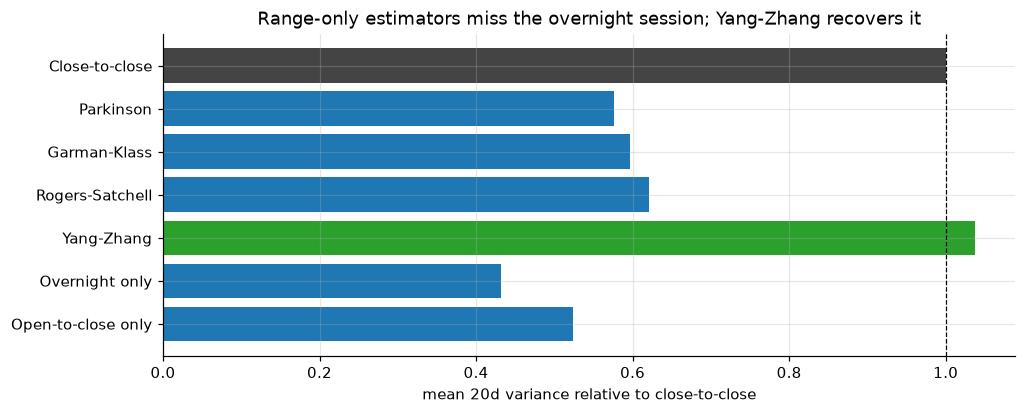

In [6]:
var20 = {name: np.exp(X[f"lv_{key}_20"]) for name, key in
         [("Close-to-close", "cc"), ("Parkinson", "park"), ("Garman-Klass", "gk"),
          ("Rogers-Satchell", "rs"), ("Yang-Zhang", "yz"), ("Overnight only", "on"), ("Open-to-close only", "id")]}
ratio = pd.Series({k: (v[DEV].mean() / var20["Close-to-close"][DEV].mean()) for k, v in var20.items()},
                  name="mean variance / close-to-close")
display(ratio.to_frame())

fig, ax = plt.subplots(figsize=(10, 3.8))
colors = ["#444" if k == "Close-to-close" else ("tab:green" if k == "Yang-Zhang" else "tab:blue") for k in ratio.index]
ax.barh(ratio.index[::-1], ratio.values[::-1], color=colors[::-1])
ax.axvline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("mean 20d variance relative to close-to-close")
ax.set_title("Range-only estimators miss the overnight session; Yang-Zhang recovers it")
savefig(fig, "estimator_bias"); plt.show()

### 5.2 Univariate information content

The table shows the Spearman rank correlation of each feature with next-period log realised variance. It is rank-based, so it is robust to tails.

Two cautions:
- Targets overlap, so these correlations have far fewer effective observations than rows.
- This is a description of the data, not a model.

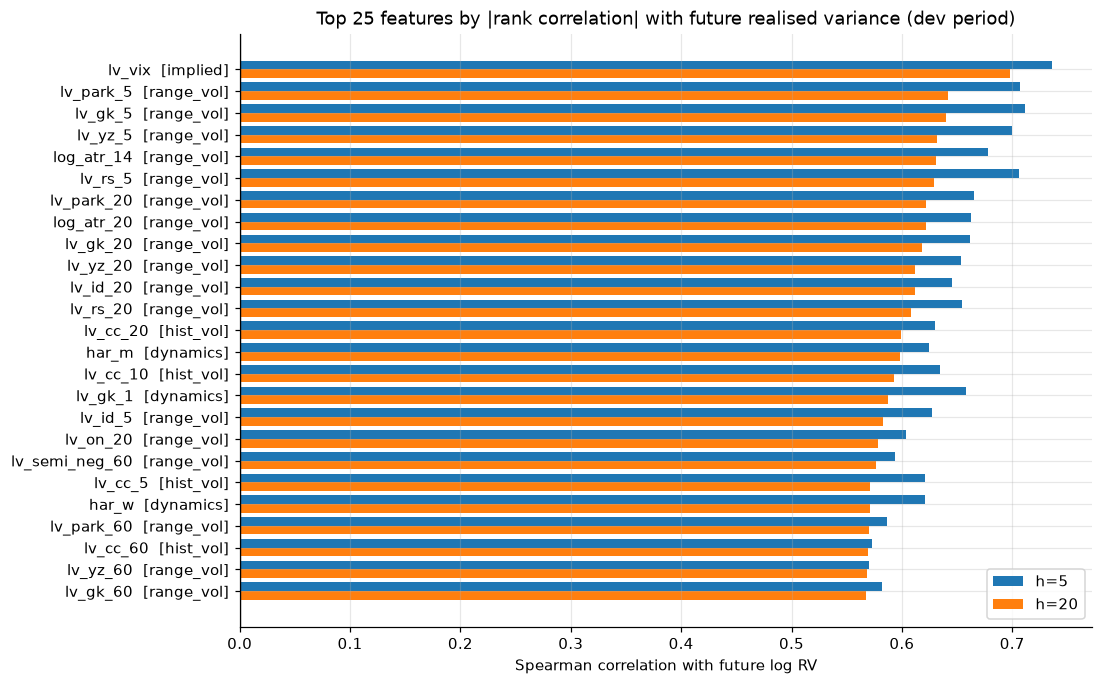

,max |IC| h=20,median |IC| h=20
group,,
returns,0.3552,0.1807
hist_vol,0.5996,0.5822
range_vol,0.642,0.5808
dynamics,0.5985,0.1739
implied,0.6983,0.2411
volume,0.2068,0.1385
momentum,0.5484,0.3869


In [7]:
ic = pd.DataFrame({f"h={h}": X.loc[DEV].corrwith(targets.loc[DEV, f"rv_logvar_{h}"], method="spearman") for h in H})
ic["group"] = catalog["group"]
ic = ic.sort_values(f"h={H[-1]}", key=np.abs, ascending=False)

top = ic.head(25)
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(top))
ax.barh(y - 0.2, top[f"h={H[0]}"], height=0.4, label=f"h={H[0]}")
ax.barh(y + 0.2, top[f"h={H[-1]}"], height=0.4, label=f"h={H[-1]}")
ax.set_yticks(y, [f"{i}  [{g}]" for i, g in zip(top.index, top.group)])
ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Spearman correlation with future log RV"); ax.legend()
ax.set_title("Top 25 features by |rank correlation| with future realised variance (dev period)")
savefig(fig, "univariate_ic"); plt.show()

group_ic = ic.assign(abs20=ic[f"h={H[-1]}"].abs()).groupby("group")["abs20"].agg(["max", "median"])
group_ic.loc[list(F.GROUPS)].rename(columns={"max": f"max |IC| h={H[-1]}", "median": f"median |IC| h={H[-1]}"})

### 5.3 Collinearity

The volatility estimators are, unsurprisingly, highly correlated with one another. Tree models handle this, but it has two consequences later:
- **Feature importance** must be read **by group** (Notebook 4 uses grouped SHAP). Within a cluster, importance is split arbitrarily between near-duplicates.
- **Linear benchmarks** (HAR) use their own small, fixed feature set, not this matrix.

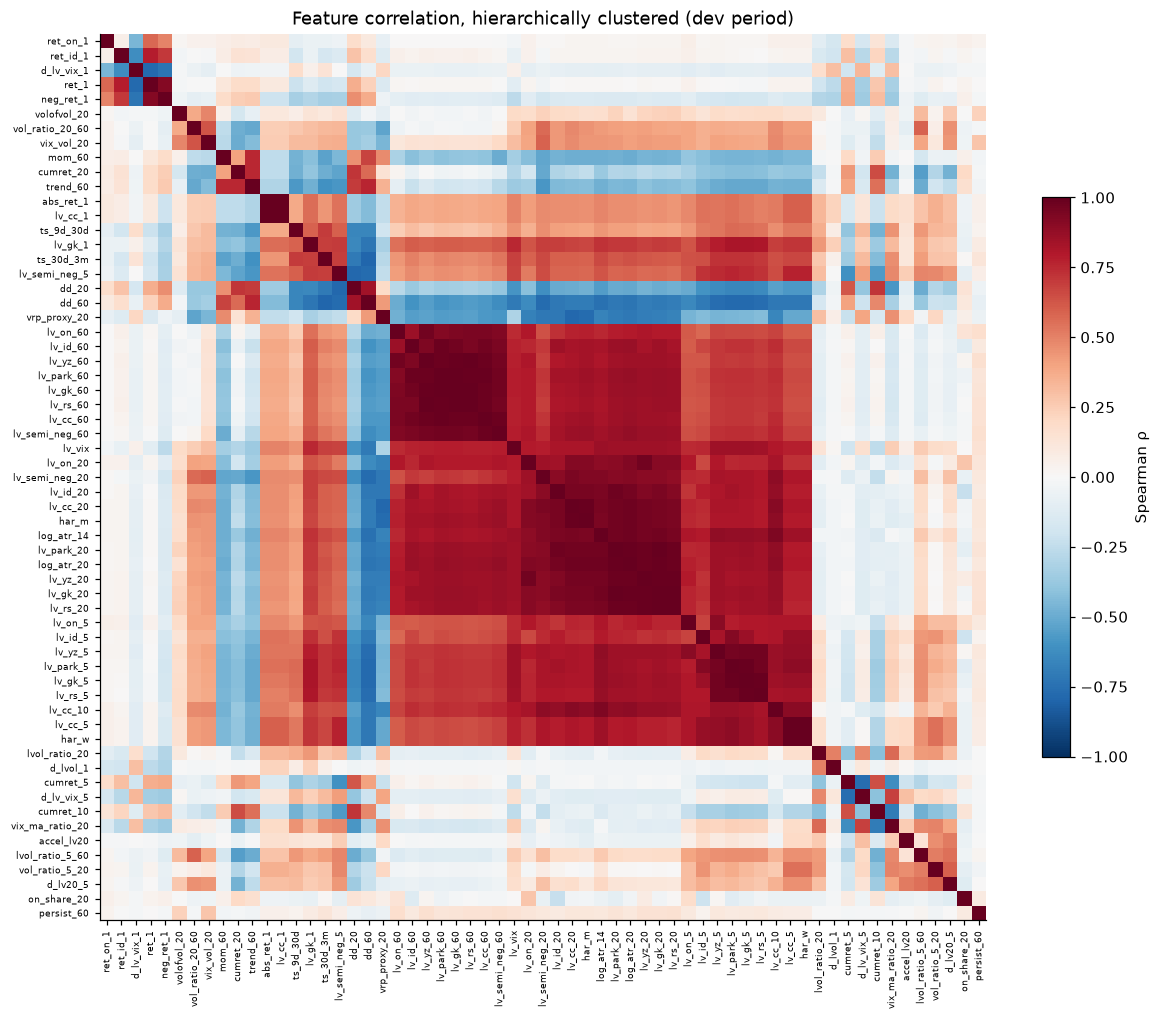

feature pairs with |ρ| > 0.95: 55 of 3721


In [8]:
corr = X.loc[DEV].corr(method="spearman")
dist = squareform(1 - corr.abs().to_numpy(), checks=False)
order = hierarchy.leaves_list(hierarchy.linkage(dist, method="average"))
c_ord = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(c_ord, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c_ord)), c_ord.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(c_ord)), c_ord.index, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman ρ")
ax.set_title("Feature correlation, hierarchically clustered (dev period)")
ax.grid(False)
savefig(fig, "feature_correlation"); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"feature pairs with |ρ| > 0.95: {(upper.abs() > 0.95).sum()} of {len(upper)}")

### 5.4 Stationarity

The table reports an Augmented Dickey-Fuller test for each feature over 2015–2022, with lag length chosen by AIC. Log-variance features are typically stationary, because volatility mean-reverts.

Features that fail are not dropped. They are flagged for two reasons:
- A model trained on a non-stationary input can degrade out of sample. The regime and stress-period analysis in Notebook 4 is where that would show up.
- They are candidates for a differenced variant if needed.

In [9]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)      # statsmodels return-type deprecation notice
    adf = pd.DataFrame({c: {"adf_stat": (res := adfuller(X.loc[DEV, c].dropna(), autolag="AIC"))[0],
                            "p_value": res[1]} for c in X.columns}).T
adf["group"] = catalog["group"]
adf["stationary_5pct"] = adf["p_value"] < 0.05
print(f"stationary at 5%: {int(adf.stationary_5pct.sum())}/{len(adf)}")
adf.sort_values("p_value", ascending=False).head(12)

stationary at 5%: 61/61


,adf_stat,p_value,group,stationary_5pct
lv_park_60,-3.092,0.02713,range_vol,True
lv_on_60,-3.198,0.02008,range_vol,True
lv_gk_60,-3.233,0.01816,range_vol,True
lv_park_20,-3.31,0.01445,range_vol,True
lv_cc_60,-3.311,0.01438,hist_vol,True
har_m,-3.337,0.01331,dynamics,True
lv_id_60,-3.377,0.01176,range_vol,True
lv_yz_20,-3.384,0.0115,range_vol,True
lv_yz_60,-3.39,0.01132,range_vol,True
lv_on_20,-3.405,0.01081,range_vol,True


### 5.5 Do the new features carry signal? Binned relationships

Each panel sorts dev-period days into deciles of one feature and plots the mean of next-20-day log realised variance in each decile. A monotone shape means the feature orders future volatility.

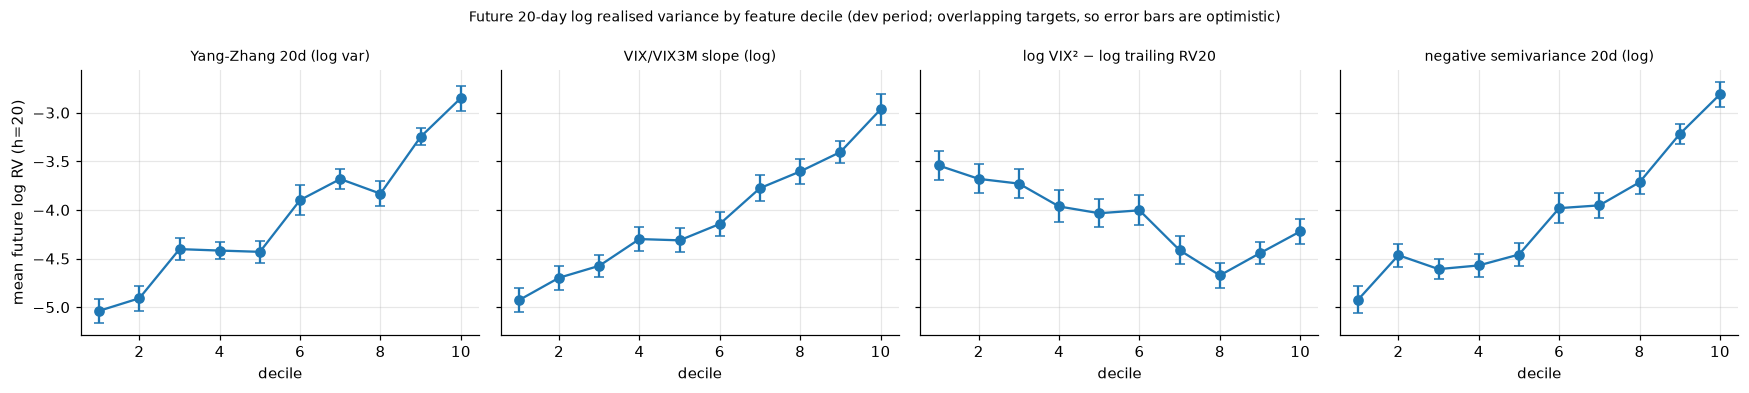

In [10]:
show = [("lv_yz_20", "Yang-Zhang 20d (log var)"), ("ts_30d_3m", "VIX/VIX3M slope (log)"),
        ("vrp_proxy_20", "log VIX² − log trailing RV20"), ("lv_semi_neg_20", "negative semivariance 20d (log)")]
show = [(f, t) for f, t in show if f in X]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.6), sharey=True)
y = targets.loc[DEV, f"rv_logvar_{H[-1]}"]
for ax, (f, title) in zip(np.atleast_1d(axes), show):
    dec = pd.qcut(X.loc[DEV, f], 10, labels=False, duplicates="drop")
    m = y.groupby(dec).mean()
    se = y.groupby(dec).std() / np.sqrt(y.groupby(dec).size())
    ax.errorbar(m.index + 1, m.values, yerr=1.96 * se.values, marker="o", capsize=3)
    ax.set_title(title, fontsize=9); ax.set_xlabel("decile")
np.atleast_1d(axes)[0].set_ylabel(f"mean future log RV (h={H[-1]})")
fig.suptitle("Future 20-day log realised variance by feature decile (dev period; overlapping targets, so error bars are optimistic)", fontsize=9)
fig.tight_layout(); savefig(fig, "binned_signal"); plt.show()

In [11]:
grp = catalog["group"]
cols = lambda *gs: [c for c in X.columns if grp[c] in gs]
feature_sets = {
    "E1_hist_vol": cols("hist_vol"),
    "E2_ohlc": cols("hist_vol", "returns", "range_vol", "dynamics"),
    "E3_plus_implied": cols("hist_vol", "returns", "range_vol", "dynamics", "implied"),
    "E4_all": list(X.columns),
    "E_noVIX": [c for c in X.columns if grp[c] != "implied"],
    "HAR": ["lv_cc_1", "har_w", "har_m"],
    "HAR_X": ["lv_cc_1", "har_w", "har_m", "lv_vix"],
}
for k, v in feature_sets.items():
    assert set(v) <= set(X.columns), k
(OUT / "feature_sets.json").write_text(json.dumps(feature_sets, indent=2))
pd.Series({k: len(v) for k, v in feature_sets.items()}, name="n_features").to_frame()

,n_features
E1_hist_vol,4
E2_ohlc,46
E3_plus_implied,54
E4_all,61
E_noVIX,53
HAR,3
HAR_X,4


## 7. Save outputs

In [12]:
X.to_parquet(OUT / "features.parquet")
catalog.to_csv(OUT / "feature_catalog.csv")
audit.assign(leaking_features=audit.leaking_features.astype(str)).to_csv(OUT / "leakage_audit.csv")
ic.to_csv(OUT / "feature_univariate_ic_dev.csv")
adf.to_csv(OUT / "feature_adf_dev.csv")

pd.testing.assert_frame_equal(pd.read_parquet(OUT / "features.parquet"), X, check_freq=False)
outputs = {n: acquire.sha256(OUT / n) for n in
           ["features.parquet", "feature_catalog.csv", "feature_sets.json", "leakage_audit.csv"]}
meta2 = {"notebook": "02_features_leakage", "data_mode": DATA_MODE,
         "inputs_sha256": {n: meta1["outputs_sha256"][n] for n in ("panel.parquet", "targets.parquet")},
         "outputs_sha256": outputs, "n_features": X.shape[1],
         "leakage_audit": {"dates": len(audit), "passed": int(audit.passed.sum())}}
(OUT / "nb02_meta.json").write_text(json.dumps(meta2, indent=2, default=str))
pd.Series(outputs, name="sha256").to_frame()

,sha256
features.parquet,58418f39d726ae208f5d53a7bd700feea44f2f93dd4667...
feature_catalog.csv,07559985054c97379d4190dd3c9c7a39f4c45d0e9c0f9c...
feature_sets.json,65a456ce4fa39d1aa4b6c841f9e4ba9bf66c2a328923e2...
leakage_audit.csv,ce32bf5b46da4b18decda630672d2d92650f641d725c63...


## 8. Findings carried forward

In [13]:
findings = {
    "n_features": X.shape[1],
    "leakage_audit_dates_passed": f"{int(audit.passed.sum())}/{len(audit)}",
    "canary_caught": bool((~canary.passed).all()),
    "dev_yz_over_cc_variance": round(float(ratio["Yang-Zhang"]), 3),
    "dev_gk_over_cc_variance": round(float(ratio["Garman-Klass"]), 3),
    "top3_features_h20": list(ic.index[:3]),
    "dev_ic_lv_vix_h20": round(float(ic.loc["lv_vix", f"h={H[-1]}"]), 3),
    "dev_ic_lv_cc_20_h20": round(float(ic.loc["lv_cc_20", f"h={H[-1]}"]), 3),
    "pairs_abs_rho_gt_0.95": int((upper.abs() > 0.95).sum()),
    "non_stationary_5pct": list(adf.index[~adf.stationary_5pct]),
}
(OUT / "nb02_findings.json").write_text(json.dumps(findings, indent=2))
pd.Series(findings, name="value").to_frame()

,value
n_features,61
leakage_audit_dates_passed,40/40
canary_caught,True
dev_yz_over_cc_variance,1.037
dev_gk_over_cc_variance,0.596
top3_features_h20,"[lv_vix, lv_park_5, lv_gk_5]"
dev_ic_lv_vix_h20,0.698
dev_ic_lv_cc_20_h20,0.6
pairs_abs_rho_gt_0.95,55
non_stationary_5pct,[]


**For the report (Section 4, Volatility estimator construction):**

1. **Leakage:** every feature passed the truncation and perturbation tests at 40 random dates with zero numerical difference, and a planted leak was caught. State this explicitly. It is the strongest single defence against "your results are too good".
2. **Estimator bias:** quote the Garman-Klass/close-to-close ratio next to the Notebook 1 overnight share. They should tell the same story: range-only estimators miss roughly the overnight fraction of variance. Yang-Zhang is the estimator to watch in the importance analysis.
3. **Implied vs historical:** compare the rank correlation of `lv_vix` with that of `lv_cc_20`. If implied variance is the stronger univariate predictor, then whether ML adds anything *beyond* VIX is the real test of H1. The E3 vs E2 ablation and HAR-X answer it.
4. **Collinearity:** report the number of near-duplicate pairs, and say that importance is analysed by group for that reason.

**Next: Notebook 3.** It fits the benchmarks (EWMA, GARCH-t, EGARCH-t, GJR-t, HAR, HAR-X) and the ML models (Random Forest, XGBoost, quantile GBM) inside the purged walk-forward. It installs `arch scikit-learn xgboost optuna` first.